# Session 03 · Freeze the ImageNet backbone

My scratch ResNet-18 reached 54.36% Top-1 accuracy on Food-101 validation. Here I keep the same architecture and train only a new classifier on the same 65,624 photos. The question is how much dish information the ImageNet features already contain.

Use a Colab GPU and run all cells. This experiment resumes at epoch boundaries in its own Drive folder. The loader uses the Session 01 split and the Session 02 crop, augmentation, batch size, seed and ten-epoch schedule. Only the validation split is scored.

In [3]:
import torch
if not torch.cuda.is_available():
    raise RuntimeError("Select a GPU runtime for full training, then run again.")
device = torch.device("cuda")
print("Training GPU:", torch.cuda.get_device_name(device))

Training GPU: Tesla T4


In [4]:
from pathlib import Path
import sys

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    PROJECT = Path("/content/drive/MyDrive/Colab Notebooks/Project 03 - Intelligent Food and Retail Product Recognition")
    sys.path.insert(0, str(PROJECT))
    from colab_food101 import stage_food
    ROOT = stage_food(PROJECT, Path("/content/project03_data"))
else:
    PROJECT = Path.cwd()
    ROOT = PROJECT / "Dataset/food-101"

Mounted at /content/drive


## Load the same photos as every later model

I verify the saved manifest fingerprint before building the loaders. A class map gives each dish a stable output index. Validation uses the same 100 images per dish for every run. I use a 224-pixel center crop at validation time. Training uses a random crop covering at least 70% of the original area and a possible horizontal flip so the classifier sees modest changes in framing. I keep the three ImageNet normalization constants per channel for the future pretrained comparison. [ResNet-18 input recipe](https://docs.pytorch.org/vision/stable/models/generated/torchvision.models.resnet18.html)

In [5]:
import hashlib
import json
import math
import time
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from torch import nn
from torch.utils.data import DataLoader, Dataset
import torchvision
from torchvision import transforms as T
from torchvision.models import resnet18, ResNet18_Weights

artifacts = PROJECT / "Artifacts"
manifest_path = artifacts / "split_manifest.csv"
fingerprint = hashlib.sha256(manifest_path.read_bytes()).hexdigest()
assert fingerprint == "86555fa81dd85aebd59d725ab89148a8a7596430889094e4566f917fe6f451fc"
table = pd.read_csv(manifest_path)
class_map = json.loads((artifacts / "class_map.json").read_text())
assert table.dish.map(class_map).eq(table.class_id).all()
classes = sorted(class_map, key=class_map.get)
assert len(classes) == 101 and [class_map[k] for k in classes] == list(range(101))
train_rows = table.loc[table.split.eq("train")]
val_rows = table.loc[table.split.eq("validation")]
assert (len(train_rows), len(val_rows)) == (65624, 10100)
eval_transform = ResNet18_Weights.IMAGENET1K_V1.transforms()
train_transform = T.Compose([T.RandomResizedCrop(224, scale=(0.7, 1.0)), T.RandomHorizontalFlip(),
                             T.ToTensor(), T.Normalize(eval_transform.mean, eval_transform.std)])

class Photos(Dataset):
    def __init__(self, rows, transform):
        self.records = list(rows[["path", "class_id"]].itertuples(index=False, name=None))
        self.transform = transform

    def __len__(self):
        return len(self.records)

    def __getitem__(self, index):
        path, label = self.records[index]
        with Image.open(ROOT / path) as photo:
            return self.transform(photo.convert("RGB")), label

train_set = Photos(train_rows, train_transform)
val_set = Photos(val_rows, eval_transform)
BATCH = 64
WORKERS = 2
SEED = 42
def loader(dataset, training, epoch=0):
    generator = torch.Generator().manual_seed(SEED + epoch)
    return DataLoader(dataset, batch_size=BATCH, shuffle=training, generator=generator,
                      num_workers=WORKERS, pin_memory=device.type == "cuda")

print(len(train_set), "training photos and", len(val_set), "validation photos")

65624 training photos and 10100 validation photos


## Build a 101-dish classifier on top of ImageNet features

The **backbone** turns each photo into 512 features. The original classifier maps these to ImageNet labels. I replace it with a linear layer that gives one score per dish. I freeze the backbone weights and keep its batch-normalization layers in evaluation mode, so their stored means and variances stay fixed too. Fine-tuning the last residual block is the next alternative if frozen features miss distinctions between dishes. [PyTorch transfer-learning tutorial](https://docs.pytorch.org/tutorials/beginner/transfer_learning_tutorial.html)

A second option would be to store the features once and train on that cache. I keep fresh random crops each epoch to match Session 02. The CNN still does a forward pass on each new crop, but only the classifier needs gradients.

In [6]:
WEIGHTS = ResNet18_Weights.IMAGENET1K_V1
def new_model():
    net = resnet18(weights=WEIGHTS)
    net.requires_grad_(False)
    torch.manual_seed(SEED)
    net.fc = nn.Linear(net.fc.in_features, len(classes))
    return net.to(device).eval()

reference = new_model()
assert [n for n, p in reference.named_parameters() if p.requires_grad] == ["fc.weight", "fc.bias"]
frozen_start = {k: v.detach().cpu().clone() for k, v in reference.state_dict().items()
                if not k.startswith("fc.")}
initial_head = reference.fc.weight.detach().cpu().clone()
print("Trainable head parameters:", sum(p.numel() for p in reference.fc.parameters()))
print("Frozen backbone parameters:", sum(p.numel() for p in reference.parameters() if not p.requires_grad))
del reference

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 177MB/s]


Trainable head parameters: 51813
Frozen backbone parameters: 11176512


## Match the baseline and measure the time

I read the completed scratch run to set the epoch count and verify the class order. I keep the same SGD settings so the comparison has the same number of training examples and updates. This compares two training recipes. Both initialization and the set of trainable weights change. I measure training and validation separately to see where a frozen backbone actually saves time.

In [7]:
LR = 0.03
use_amp = device.type == "cuda"
def optimizer_for(net):
    return torch.optim.SGD(net.fc.parameters(), lr=LR, momentum=0.9, weight_decay=1e-4)

def train_batch(net, optimizer, scaler, batch):
    images, labels = (value.to(device, non_blocking=True) for value in batch)
    optimizer.zero_grad(set_to_none=True)
    with torch.autocast(device_type=device.type, enabled=use_amp):
        loss = nn.functional.cross_entropy(net(images), labels)
    scaler.scale(loss).backward()
    scaler.step(optimizer)
    scaler.update()
    return loss.detach(), len(labels)

def synchronize():
    if device.type == "cuda":
        torch.cuda.synchronize(device)


baseline = json.loads((artifacts / "session02_resnet18_scratch/validation.json").read_text())
assert baseline["class_order"] == classes and baseline["config"]["manifest"] == fingerprint
epochs = len(baseline["history"])
assert epochs == baseline["budget"]["epochs"] == 10
run_dir = artifacts / "session03_resnet18_frozen"
run_dir.mkdir(exist_ok=True)
latest = run_dir / "latest.pt"
config = dict(baseline["config"], initial_weights="IMAGENET1K_V1", trainable="fc",
              batch_norm="eval", recipe=1)
budget = dict(epochs=epochs)
print("Matched training epochs:", epochs)

Matched training epochs: 10


## Train the head and verify the backbone

The checkpoint contains the trained head, SGD momentum, gradient scaler, history and best head. Torchvision supplies the named backbone weights on resume. I compare every frozen weight and batch-normalization buffer with its starting value before committing each epoch. I select the epoch with the highest validation macro F1, as I did for the scratch model.

In [8]:
def evaluate(net, batches):
    net.eval()
    pairs, top5, total_loss = [], 0, 0.0
    with torch.inference_mode():
        for images, labels in batches:
            images, labels = images.to(device), labels.to(device)
            with torch.autocast(device_type=device.type, enabled=use_amp):
                logits = net(images)
                loss = nn.functional.cross_entropy(logits, labels, reduction="sum")
            top = logits.topk(5, dim=1).indices
            top5 += int(top.eq(labels[:, None]).any(dim=1).sum())
            pairs.append(torch.stack([labels, top[:, 0]], dim=1).cpu())
            total_loss += loss.item()
    pairs = torch.cat(pairs)
    k = len(classes)
    matrix = torch.bincount(pairs[:, 0] * k + pairs[:, 1], minlength=k*k).reshape(k, k)
    hits = matrix.diag()
    per_f1 = 2 * hits / (matrix.sum(0) + matrix.sum(1)).clamp_min(1)
    return dict(val_loss=total_loss / len(pairs), top1=hits.sum().item() / len(pairs),
                top5=top5 / len(pairs), macro_f1=per_f1.mean().item()), matrix

def save_checkpoint(value, path):
    pending = path.with_suffix(".pending")
    torch.save(value, pending)
    pending.replace(path)

def train_epochs(stop_epoch):
    net = new_model()
    opt = optimizer_for(net)
    scaler = torch.amp.GradScaler(device.type, enabled=use_amp)
    state = torch.load(latest, map_location="cpu", weights_only=True) if latest.exists() else None
    history, best = [], None
    if state:
        if state["config"] != config or state["budget"] != budget:
            raise ValueError("Checkpoint configuration changed.")
        net.fc.load_state_dict(state["head"])
        opt.load_state_dict(state["optimizer"])
        scaler.load_state_dict(state["scaler"])
        history, best = state["history"], state["best"]
        del state
    for epoch in range(len(history) + 1, stop_epoch + 1):
        torch.manual_seed(SEED + epoch)
        start = time.perf_counter()
        net.eval()
        net.fc.train()
        loss_sum = torch.zeros((), device=device)
        count = 0
        for batch in loader(train_set, True, epoch):
            loss, n = train_batch(net, opt, scaler, batch)
            loss_sum += loss * n
            count += n
        assert count == len(train_set)
        train_loss = loss_sum.item() / count
        train_seconds = time.perf_counter() - start
        validation_start = time.perf_counter()
        scores, matrix = evaluate(net, loader(val_set, False))
        assert matrix.sum().item() == len(val_set)
        validation_seconds = time.perf_counter() - validation_start
        row = dict(train_seconds=train_seconds, validation_seconds=validation_seconds, epoch=epoch, train_loss=train_loss, seconds=time.perf_counter()-start, **scores)
        if not all(math.isfinite(v) for v in row.values()):
            raise ValueError(f"Non-finite result at epoch {epoch}: {row}")
        for name, value in net.state_dict().items():
            if name in frozen_start:
                assert torch.equal(value.cpu(), frozen_start[name]), name
        assert not torch.equal(net.fc.weight.detach().cpu(), initial_head)
        history.append(row)
        if best is None or scores["macro_f1"] > best["macro_f1"]:
            best = dict(epoch=epoch, macro_f1=scores["macro_f1"], matrix=matrix,
                        weights={k: v.detach().cpu().clone() for k,v in net.fc.state_dict().items()})
        save_checkpoint(dict(head=net.fc.state_dict(), optimizer=opt.state_dict(), scaler=scaler.state_dict(),
                             config=config, history=history, best=best, budget=budget), latest)
        print(f"Epoch {epoch}/{stop_epoch}: {row}", flush=True)
    return history, best

history, best = train_epochs(budget["epochs"])

Epoch 1/10: {'train_seconds': 357.16259152199984, 'validation_seconds': 57.565614245999996, 'epoch': 1, 'train_loss': 2.542628744818969, 'seconds': 414.72821131700005, 'val_loss': 2.255578212171498, 'top1': 0.4806930693069307, 'top5': 0.7437623762376238, 'macro_f1': 0.47616592049598694}
Epoch 2/10: {'train_seconds': 336.8861885460001, 'validation_seconds': 57.583958420000044, 'epoch': 2, 'train_loss': 2.2134294427343653, 'seconds': 394.4701488070002, 'val_loss': 2.1600281894797146, 'top1': 0.5082178217821782, 'top5': 0.77, 'macro_f1': 0.5040329694747925}
Epoch 3/10: {'train_seconds': 326.93671689100006, 'validation_seconds': 54.10596635599995, 'epoch': 3, 'train_loss': 2.135797069288675, 'seconds': 381.04269454099995, 'val_loss': 2.1757321533354204, 'top1': 0.514950495049505, 'top5': 0.7642574257425743, 'macro_f1': 0.5044122338294983}
Epoch 4/10: {'train_seconds': 320.04689581699995, 'validation_seconds': 52.36481436699978, 'epoch': 4, 'train_loss': 2.1010591589967085, 'seconds': 372.4

## Revisit the scratch model’s hardest pair

I reload the best head on the ImageNet backbone and reproduce the selected validation confusion matrix. Then I compare both models on the same 100 Greek salad photos. In Session 02, 27 were classified as caprese salad. I also report any new leading confusion and export the whole selected model for Session 04.

{'scratch_validation': {'val_loss': 1.8094881514747545, 'top1': 0.5435643564356436, 'top5': 0.8016831683168317, 'macro_f1': 0.5437070727348328}, 'scratch_greek_as_caprese': 27, 'frozen_greek_as_caprese': 3, 'delta': {'top1': -0.025445544554455468, 'top5': -0.0218811881188119, 'macro_f1': -0.029069364070892334}, 'scratch_epoch_seconds': 3886.882169944999, 'frozen_epoch_seconds': 3823.851309625001, 'device': 'Tesla T4', 'torch': '2.14.1+cu130', 'torchvision': '0.29.1+cu130'}


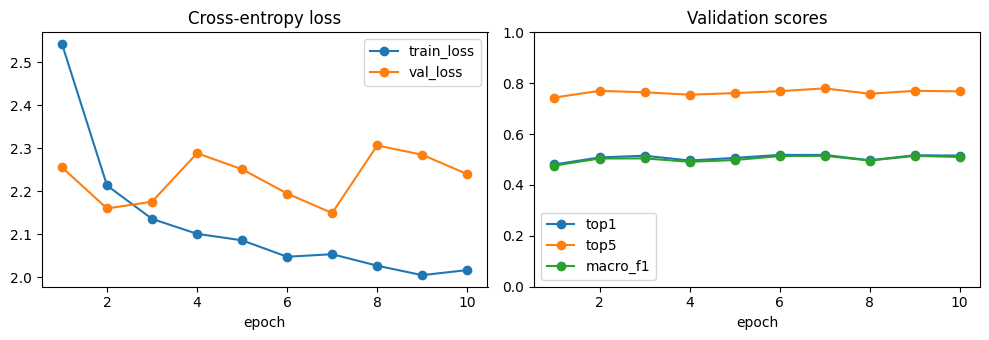

Selected epoch 7 {'val_loss': 2.1493590447454167, 'top1': 0.5181188118811881, 'top5': 0.7798019801980198, 'macro_f1': 0.5146377086639404}
Most frequent validation error: {'actual': 'hamburger', 'predicted': 'pulled_pork_sandwich', 'count': 44, 'examples': ['images/hamburger/100057.jpg', 'images/hamburger/1126075.jpg', 'images/hamburger/116741.jpg', 'images/hamburger/1170104.jpg', 'images/hamburger/1208447.jpg']}


In [9]:
selected = new_model()
selected.fc.load_state_dict(best["weights"])
scores, matrix = evaluate(selected, loader(val_set, False))
assert torch.equal(matrix, best["matrix"]), "Reloaded validation predictions changed the confusion matrix."
errors = matrix.clone()
errors.fill_diagonal_(0)
worst = None
if errors.max() > 0:
    true_id, pred_id = divmod(int(errors.argmax()), len(classes))
    worst = dict(actual=classes[true_id], predicted=classes[pred_id], count=int(errors.max()))
    candidates = val_rows[val_rows.class_id.eq(true_id)]
    examples = []
    pos = 0
    with torch.inference_mode():
        for images, _ in loader(Photos(candidates, eval_transform), False):
            with torch.autocast(device_type=device.type, enabled=use_amp):
                predicted = selected(images.to(device)).topk(5, dim=1).indices[:, 0].cpu()
            for offset in (predicted == pred_id).nonzero().flatten().tolist():
                examples.append(candidates.iloc[pos + offset].path)
            pos += len(images)
    worst["examples"] = examples[:5]

save_checkpoint(dict(weights=selected.state_dict(), classes=classes, config=config, epoch=best["epoch"]),
                run_dir / "best.pt")
summary = dict(config=config, budget=budget, selected_epoch=best["epoch"], validation=scores,
               top_confusion=worst, history=history, class_order=classes, confusion_matrix=matrix.tolist())
g, h = class_map["greek_salad"], class_map["caprese_salad"]
summary["baseline_comparison"] = {
    "scratch_validation": baseline["validation"],
    "scratch_greek_as_caprese": baseline["confusion_matrix"][g][h],
    "frozen_greek_as_caprese": matrix[g, h].item(),
    "delta": {k: scores[k] - baseline["validation"][k] for k in ("top1","top5","macro_f1")},
    "scratch_epoch_seconds": sum(row["seconds"] for row in baseline["history"]),
    "frozen_epoch_seconds": sum(row["seconds"] for row in history),
    "device": torch.cuda.get_device_name() if use_amp else "CPU",
    "torch": str(torch.__version__), "torchvision": str(torchvision.__version__),
}
print(summary["baseline_comparison"])
pending = run_dir / "validation.json.tmp"
pending.write_text(json.dumps(summary, indent=2), encoding="utf-8")
pending.replace(run_dir / "validation.json")
frame = pd.DataFrame(history).set_index("epoch")
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
frame[["train_loss", "val_loss"]].plot(ax=axes[0], marker="o", title="Cross-entropy loss")
frame[["top1", "top5", "macro_f1"]].plot(ax=axes[1], marker="o", ylim=(0,1), title="Validation scores")
fig.tight_layout()
fig.savefig(run_dir / "learning_curves.png")
plt.show()
print("Selected epoch", best["epoch"], scores)
print("Most frequent validation error:", worst)